In [2]:
pip install geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.7/24.7 MB 466.1 kB/s  0:01:05 eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 404.3 kB/s  0:00:12394.7 kB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 923.3 kB/s  0:00:018.5 kB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]━ 3/4 [geopandas]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, requests

base = "https://raw.githubusercontent.com/datameet/maps/master/States/Admin2"
for ext in ["shp", "shx", "dbf", "prj"]:
    path = f"Admin2.{ext}"
    if not os.path.exists(path):
        r = requests.get(f"{base}.{ext}", timeout=120)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
    print(path, os.path.getsize(path) // 1024, "KB")

Admin2.shp 16741 KB
Admin2.shx 0 KB
Admin2.dbf 1 KB
Admin2.prj 0 KB


                  station   role  distance_km
R K Puram, Delhi (source) Source          0.0
               ITO, Delhi Ring 0          9.0
         Amritsar, Punjab Ring 1        406.0
       Jodhpur, Rajasthan Ring 1        482.0
    Dehradun, Uttarakhand Ring 1        211.0
               Jammu, J&K Ring 1        514.0
      Mumbai, Maharashtra Ring 2       1144.0
       Patia, Bhubaneswar Ring 2       1263.0
    Silk Board, Bengaluru Ring 2       1740.0
          Guwahati, Assam Ring 2       1459.0
        Vellarada, kerela Ring 3       2237.0


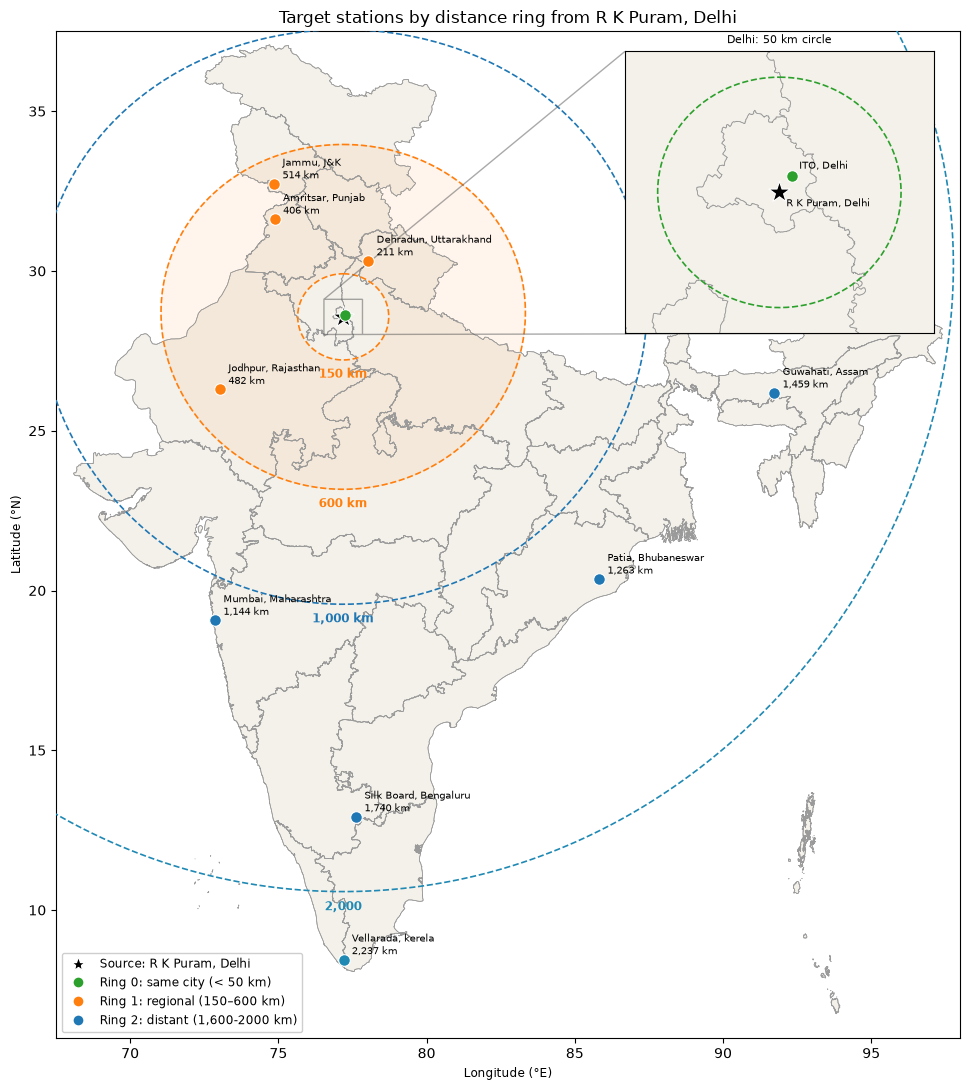

In [10]:
# ===== Station selection map: India states + distance rings around Delhi =====
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

STATES_FILE = "Admin2.shp"     # India states (datameet/maps, States/Admin2.*)

# station coordinates: APPROXIMATE - replace with the exact values from CPCB
STATIONS = pd.DataFrame([
    # name,                       lat,     lon,     role
    ("R K Puram, Delhi (source)", 28.5633, 77.1869, "Source"),
    ("ITO, Delhi",                28.6286, 77.2410, "Ring 0"),
    ("Amritsar, Punjab",          31.6200, 74.8765, "Ring 1"),
    ("Jodhpur, Rajasthan",        26.2920, 73.0310, "Ring 1"),
    ("Dehradun, Uttarakhand",     30.3165, 78.0322, "Ring 1"),
    ("Jammu, J&K",                32.7266, 74.8570, "Ring 1"),
    ("Mumbai, Maharashtra",       19.0650, 72.8650, "Ring 2"),
    ("Patia, Bhubaneswar",        20.3550, 85.8200, "Ring 2"),
    ("Silk Board, Bengaluru",     12.9170, 77.6230, "Ring 2"),
    ("Guwahati, Assam",           26.1800, 91.7300, "Ring 2"),
], columns=["station", "lat", "lon", "role"])

SRC_LAT, SRC_LON = 28.5633, 77.1869
R_EARTH = 6371.0

def distance_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(a))

def circle(lat, lon, radius_km, n=360):
    """Points of a circle of given radius (km) around (lat, lon)."""
    b = np.radians(np.linspace(0, 360, n))
    d = radius_km / R_EARTH
    p1, l1 = np.radians(lat), np.radians(lon)
    p2 = np.arcsin(np.sin(p1) * np.cos(d) + np.cos(p1) * np.sin(d) * np.cos(b))
    l2 = l1 + np.arctan2(np.sin(b) * np.sin(d) * np.cos(p1), np.cos(d) - np.sin(p1) * np.sin(p2))
    return np.degrees(l2), np.degrees(p2)

STATIONS["distance_km"] = distance_km(SRC_LAT, SRC_LON, STATIONS.lat, STATIONS.lon).round(0)
print(STATIONS[["station", "role", "distance_km"]].to_string(index=False))

# ---------- map ----------
states = gpd.read_file(STATES_FILE)
RINGS = [(50, "Ring 0: same city (< 50 km)"),
         (600, "Ring 1: regional (150–600 km)"),
         (1000, "Ring 2: distant (1,600-2000 km)"),
        (2000, "Ring 2: distant (> 2,000 km)")]
ROLE_STYLE = {"Source": dict(c="black", marker="*", s=260),
              "Ring 0": dict(c="#2ca02c", marker="o", s=70),
              "Ring 1": dict(c="#ff7f0e", marker="o", s=70),
              "Ring 2": dict(c="#1f77b4", marker="o", s=70),
             "Ring 3": dict(c="#1f89b4", marker="o", s=70)}

fig, ax = plt.subplots(figsize=(10, 11))
states.plot(ax=ax, color="#f4f1ea", edgecolor="#9a9a9a", linewidth=0.5)

# shaded ring bands
lo150 = circle(SRC_LAT, SRC_LON, 150)
lo600 = circle(SRC_LAT, SRC_LON, 600)
ax.fill(*lo600, color="#ff7f0e", alpha=0.07)
ax.fill(*lo150, color="#f4f1ea", alpha=1.0, zorder=1)       # hollow centre of ring 1
states.boundary.plot(ax=ax, color="#9a9a9a", linewidth=0.5, zorder=2)

for r, lab, col in [(150, "150 km", "#ff7f0e"), (600, "600 km", "#ff7f0e"), (1000, "1,000 km", "#1f77b4"),(2000, "2,000" ,"#1f89b4")]:
    x, y = circle(SRC_LAT, SRC_LON, r)
    ax.plot(x, y, ls="--", lw=1.2, color=col, zorder=3)
    ax.text(SRC_LON, SRC_LAT - r / 111 - 0.55, lab, ha="center", fontsize=8.5, color=col,
            fontweight="bold", zorder=5)                     # label below each circle

for role, style in ROLE_STYLE.items():
    s = STATIONS[STATIONS.role == role]
    ax.scatter(s.lon, s.lat, edgecolor="white", linewidth=0.8, zorder=6, label=role, **style)

for _, r in STATIONS.iterrows():
    if r.role in ("Source", "Ring 0"):
        continue
    ax.annotate(f"{r.station}\n{int(r.distance_km):,} km", (r.lon, r.lat), xytext=(6, 4),
                textcoords="offset points", fontsize=7.5, zorder=7)

ax.set_xlim(67.5, 98); ax.set_ylim(6, 37.5)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title("Target stations by distance ring from R K Puram, Delhi", fontsize=12)
handles = [plt.Line2D([], [], marker=ROLE_STYLE[k]["marker"], color="w", markerfacecolor=ROLE_STYLE[k]["c"],
                      markersize=11 if k == "Source" else 8, label=lab)
           for k, lab in [("Source", "Source: R K Puram, Delhi"), ("Ring 0", RINGS[0][1]),
                          ("Ring 1", RINGS[1][1]), ("Ring 2", RINGS[2][1])]]
ax.legend(handles=handles, loc="lower left", fontsize=8.5, framealpha=0.95)

# inset: zoom on Delhi (ring 0)
ins = ax.inset_axes([0.62, 0.70, 0.36, 0.28])
states.plot(ax=ins, color="#f4f1ea", edgecolor="#9a9a9a", linewidth=0.6)
x, y = circle(SRC_LAT, SRC_LON, 50)
ins.plot(x, y, ls="--", lw=1.2, color="#2ca02c")
for role in ("Source", "Ring 0"):
    s = STATIONS[STATIONS.role == role]
    ins.scatter(s.lon, s.lat, edgecolor="white", linewidth=0.8, zorder=5, **ROLE_STYLE[role])
for _, r in STATIONS[STATIONS.role.isin(["Source", "Ring 0"])].iterrows():
    ins.annotate(r.station.replace(" (source)", ""), (r.lon, r.lat), xytext=(5, -10 if r.role == "Source" else 5),
                 textcoords="offset points", fontsize=7)
ins.set_xlim(SRC_LON - 0.65, SRC_LON + 0.65); ins.set_ylim(SRC_LAT - 0.55, SRC_LAT + 0.55)
ins.set_xticks([]); ins.set_yticks([]); ins.set_xlabel(""); ins.set_ylabel("")
ins.set_title("Delhi: 50 km circle", fontsize=8)
ax.indicate_inset_zoom(ins, edgecolor="#555555")

plt.tight_layout()
plt.savefig("station_rings_map.png", dpi=800)
plt.show()

                  station   role       lat       lon  distance_km
R K Puram, Delhi (source) Source 28.563300 77.186900          0.0
    Silk Board, Bengaluru Ring 2 12.916940 77.621800       1740.0
    Dehradun, Uttarakhand Ring 1 30.267388 78.044936        207.0
               ITO, Delhi Ring 0 28.628600 77.241000          9.0
          Guwahati, Assam Ring 2 26.181742 91.780630       1464.0
         Ludhiana, Punjab Ring 1 30.900000 75.850000        290.0
          Mandor, Jodhpur Ring 1 26.353500 73.033100        478.0
       Patia, Bhubaneswar Ring 2 20.358824 85.833267       1263.0


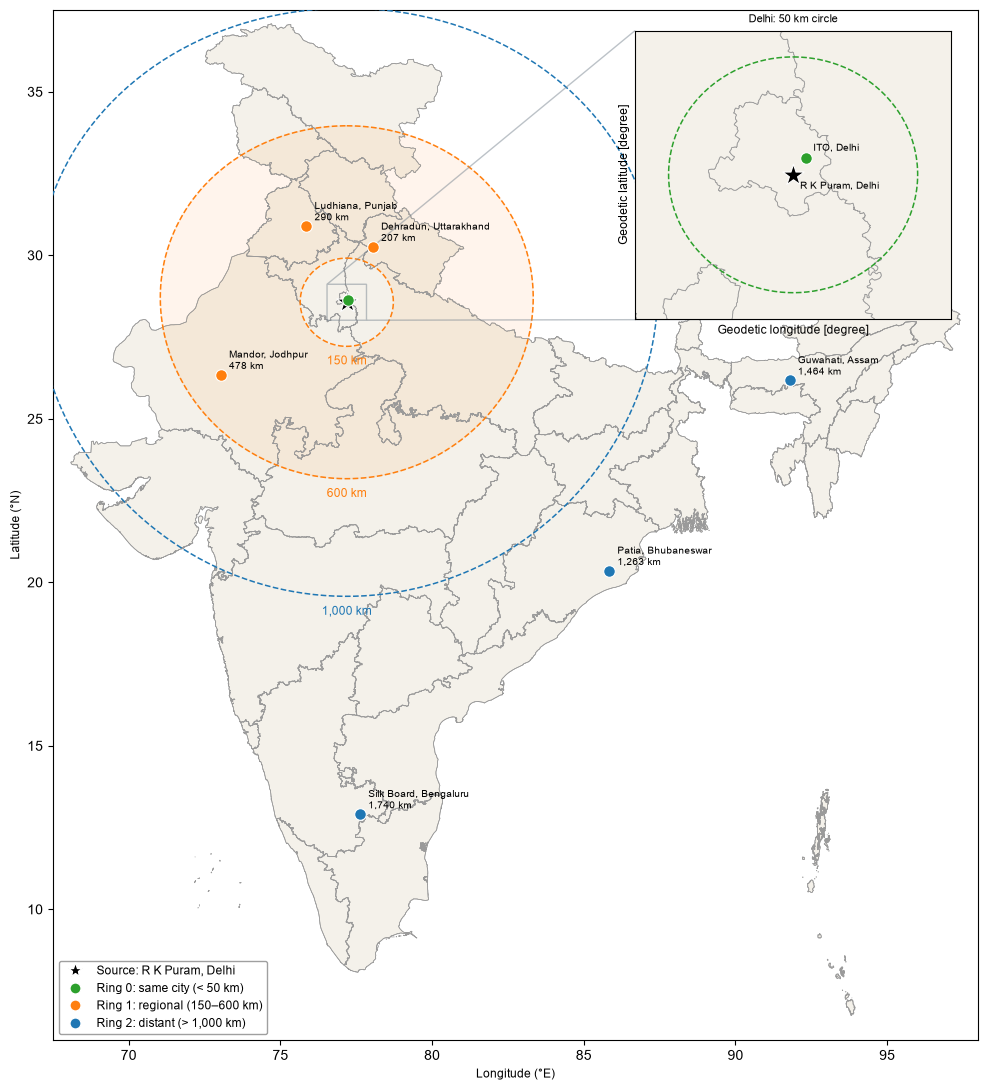

In [5]:
# ===== Fig. 1: Station map – India states + distance rings around R K Puram =====
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

STATES_FILE = "Admin2.shp"                                   # India states (datameet/maps)
SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
SRC_LAT, SRC_LON = 28.5633, 77.1869                          # R K Puram – same as SRC_LAT/SRC_LON in Part H
R_EARTH = 6371.0

# ---------- stations: exact coordinates from the summary files (written by Part H) ----------
NAMES = {"Delhi_ITO": "ITO, Delhi",
         "Punjab_Ludhiana": "Ludhiana, Punjab",
         "Dehradun": "Dehradun, Uttarakhand",
         "Rajesthan_jodhpur": "Mandor, Jodhpur",
         "bhubaneswar_PATIA": "Patia, Bhubaneswar",
         "Guwahati": "Guwahati, Assam",
         "Bengluru_SILK": "Silk Board, Bengaluru"}

rows = [("R K Puram, Delhi (source)", SRC_LAT, SRC_LON, "Source")]
for f in sorted(glob.glob(f"{SUMMARY_DIR}/summary_*.csv")):
    s = pd.read_csv(f).iloc[0]
    if s["station"] in NAMES:
        rows.append((NAMES[s["station"]], s["lat"], s["lon"], s["ring"].split(" (")[0]))
STATIONS = pd.DataFrame(rows, columns=["station", "lat", "lon", "role"])

def distance_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(a))

def circle(lat, lon, radius_km, n=360):
    """Points of a circle of given radius (km) around (lat, lon)."""
    b = np.radians(np.linspace(0, 360, n))
    d = radius_km / R_EARTH
    p1, l1 = np.radians(lat), np.radians(lon)
    p2 = np.arcsin(np.sin(p1) * np.cos(d) + np.cos(p1) * np.sin(d) * np.cos(b))
    l2 = l1 + np.arctan2(np.sin(b) * np.sin(d) * np.cos(p1), np.cos(d) - np.sin(p1) * np.sin(p2))
    return np.degrees(l2), np.degrees(p2)

STATIONS["distance_km"] = distance_km(SRC_LAT, SRC_LON, STATIONS.lat, STATIONS.lon).round(0)
print(STATIONS[["station", "role", "lat", "lon", "distance_km"]].to_string(index=False))

# ---------- style (original colours) ----------
INK, LAND, EDGE = "black", "#f4f1ea", "#9a9a9a"
C0, C1, C2 = "#2ca02c", "#ff7f0e", "#1f77b4"
RINGS = {"Ring 0": "Ring 0: same city (< 50 km)",
         "Ring 1": "Ring 1: regional (150–600 km)",
         "Ring 2": "Ring 2: distant (> 1,000 km)"}
ROLE_STYLE = {"Source": dict(c=INK, marker="*", s=260),
              "Ring 0": dict(c=C0, marker="o", s=70),
              "Ring 1": dict(c=C1, marker="o", s=70),
              "Ring 2": dict(c=C2, marker="o", s=70)}
plt.rcParams.update({"font.family": "Arial", "svg.fonttype": "none"})   # editable text in SVG

# ---------- map ----------
states = gpd.read_file(STATES_FILE)
fig, ax = plt.subplots(figsize=(10, 11))
states.plot(ax=ax, color=LAND, edgecolor=EDGE, linewidth=0.5)

# shaded Ring 1 band (150–600 km)
ax.fill(*circle(SRC_LAT, SRC_LON, 600), color=C1, alpha=0.08, zorder=1)
ax.fill(*circle(SRC_LAT, SRC_LON, 150), color=LAND, alpha=1.0, zorder=1)
states.boundary.plot(ax=ax, color=EDGE, linewidth=0.5, zorder=2)

for r, lab, col in [(150, "150 km", C1), (600, "600 km", C1), (1000, "1,000 km", C2)]:
    x, y = circle(SRC_LAT, SRC_LON, r)
    ax.plot(x, y, ls="--", lw=1.1, color=col, zorder=3)
    ax.text(SRC_LON, SRC_LAT - r / 111 - 0.55, lab, ha="center", fontsize=8.5, color=col, zorder=5)

for role, style in ROLE_STYLE.items():
    s = STATIONS[STATIONS.role == role]
    ax.scatter(s.lon, s.lat, edgecolor="white", linewidth=0.8, zorder=6, **style)

for _, r in STATIONS.iterrows():
    if r.role in ("Source", "Ring 0"):
        continue
    ax.annotate(f"{r.station}\n{int(r.distance_km):,} km", (r.lon, r.lat), xytext=(6, 4),
                textcoords="offset points", fontsize=7.5, color=INK, zorder=7)

ax.set_xlim(67.5, 98); ax.set_ylim(6, 37.5)
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
handles = [plt.Line2D([], [], marker=ROLE_STYLE[k]["marker"], color="w", markerfacecolor=ROLE_STYLE[k]["c"],
                      markersize=11 if k == "Source" else 8, label=lab)
           for k, lab in [("Source", "Source: R K Puram, Delhi")] + list(RINGS.items())]
ax.legend(handles=handles, loc="lower left", fontsize=8.5, framealpha=0.95, edgecolor=EDGE)

# ---------- inset: Delhi (Ring 0) ----------
ins = ax.inset_axes([0.62, 0.70, 0.36, 0.28])
states.plot(ax=ins, color=LAND, edgecolor=EDGE, linewidth=0.6)
ins.plot(*circle(SRC_LAT, SRC_LON, 50), ls="--", lw=1.1, color=C0)
for role in ("Source", "Ring 0"):
    s = STATIONS[STATIONS.role == role]
    ins.scatter(s.lon, s.lat, edgecolor="white", linewidth=0.8, zorder=5, **ROLE_STYLE[role])
for _, r in STATIONS[STATIONS.role.isin(["Source", "Ring 0"])].iterrows():
    ins.annotate(r.station.replace(" (source)", ""), (r.lon, r.lat),
                 xytext=(5, -10 if r.role == "Source" else 5), textcoords="offset points", fontsize=7, color=INK)
ins.set_xlim(SRC_LON - 0.65, SRC_LON + 0.65); ins.set_ylim(SRC_LAT - 0.55, SRC_LAT + 0.55)
ins.set_xticks([]); ins.set_yticks([])
ins.set_title("Delhi: 50 km circle", fontsize=8)
ax.indicate_inset_zoom(ins, edgecolor="#7A8691")

plt.tight_layout()
plt.savefig("Fig1_station_map.svg")
plt.savefig("Fig1_station_map.png", dpi=800)
plt.show()